# Розвідувальний аналіз даних (EDA)

Прогноз результату футбольного матчу (H — перемога господарів, D — нічия, A — перемога гостей).
Працюємо з **сирими** даними з `data/raw/`:

- `Matches.csv` — клубні матчі 2000–2026 (xgabora/Club-Football-Match-Data): Elo, форма, рахунок, статистика, коефіцієнти БК;
- `EloRatings.csv` — історія клубних рейтингів Elo;
- `results.csv`, `shootouts.csv`, `former_names.csv` — матчі національних збірних з 1872 року (martj42/international_results).

Мета ноутбука — зрозуміти, що в даних є, де дірки, і що з цього випливає для моделі.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# корінь проєкту: поточна папка або батьківська, де є src/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config

RAW, FIG = config.RAW, config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 120, "savefig.bbox": "tight"})
PAL = {"H": "#2E7D32", "D": "#9E9E9E", "A": "#C62828"}

def save(fig, name):
    fig.savefig(FIG / f"eda_{name}.png")
    print("збережено:", f"reports/figures/eda_{name}.png")

## 1. Клубні матчі: розмір, діапазон дат, сезони

In [2]:
m = pd.read_csv(RAW / "Matches.csv", low_memory=False)
m["MatchDate"] = pd.to_datetime(m["MatchDate"])
m = m[m["FTResult"].isin(config.CLASSES)].copy()          # 4 рядки без результату відкидаємо
m["season"] = np.where(m["MatchDate"].dt.month >= 7, m["MatchDate"].dt.year, m["MatchDate"].dt.year - 1)
elo = pd.read_csv(RAW / "EloRatings.csv", parse_dates=["date"])
print(f"Matches.csv: {len(m):,} матчів, {m.shape[1]} колонок, {m['Division'].nunique()} ліг")
print(f"Дати: {m['MatchDate'].min().date()} … {m['MatchDate'].max().date()}")
print(f"Команд: {pd.concat([m.HomeTeam, m.AwayTeam]).nunique():,}")
print(f"EloRatings.csv: {len(elo):,} записів, {elo['club'].nunique():,} клубів, {elo['date'].min().date()} … {elo['date'].max().date()}")

Matches.csv: 238,854 матчів, 49 колонок, 38 ліг
Дати: 2000-07-28 … 2026-09-03
Команд: 1,233
EloRatings.csv: 273,972 записів, 984 клубів, 2000-07-01 … 2026-09-01


## 2. Пропуски по колонках
Статистика матчу (удари, кутові, картки) і коефіцієнти є далеко не скрізь. Важливо: статистику **цього** матчу як ознаку брати не можна (витік) — але її пропуски впливають на ковзні ознаки за попередні матчі.

In [3]:
miss = (m.isna().mean() * 100).sort_values(ascending=False).round(1)
print(miss[miss > 0].to_string())

MatchTime      55.0
C_LTA          52.9
C_LTH          52.9
C_VAD          52.9
C_VHD          52.9
C_HTB          52.9
C_PHB          52.9
HomeTarget     49.1
AwayTarget     49.1
HomeFouls      49.0
AwayFouls      49.0
AwayCorners    48.9
HomeCorners    48.9
HomeShots      48.7
AwayShots      48.7
AwayRed        46.6
HomeYellow     46.6
HomeRed        46.6
AwayYellow     46.6
AwayElo        37.3
HomeElo        37.2
Under25        34.4
MaxUnder25     34.4
Over25         34.4
MaxOver25      34.4
HandiAway      31.0
HandiHome      31.0
HandiSize      30.9
HTResult       22.8
HTAway         22.8
HTHome         22.8
MaxAway        11.6
MaxDraw        11.6
MaxHome        11.6
OddAway         1.3
OddHome         1.3
OddDraw         1.3
Form5Home       0.6
Form5Away       0.6
Form3Home       0.6
Form3Away       0.6


збережено: reports/figures/eda_missing_by_season.png


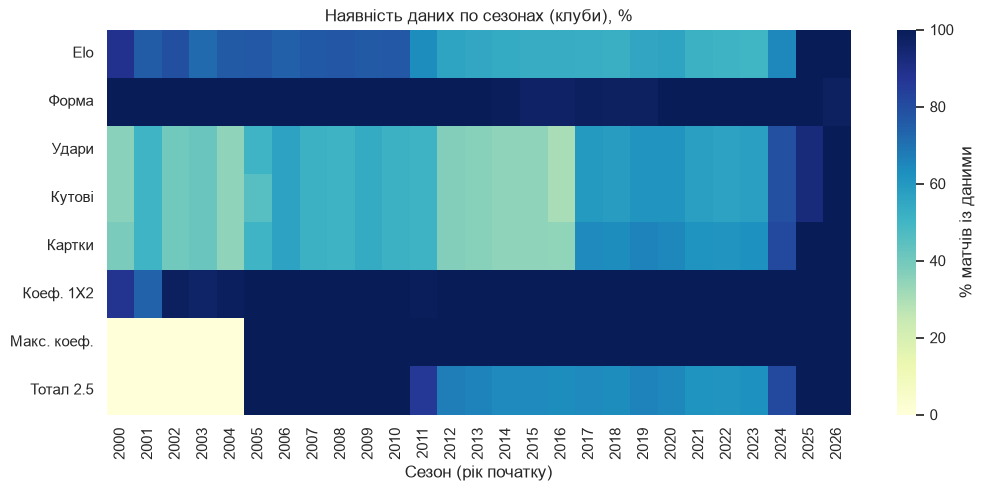

In [4]:
groups = {"Elo": ["HomeElo", "AwayElo"], "Форма": ["Form5Home"], "Удари": ["HomeShots"], "Кутові": ["HomeCorners"],
          "Картки": ["HomeYellow"], "Коеф. 1X2": ["OddHome"], "Макс. коеф.": ["MaxHome"], "Тотал 2.5": ["Over25"]}
avail = pd.DataFrame({k: m.groupby("season")[v[0]].apply(lambda s: s.notna().mean()) for k, v in groups.items()})
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(avail.T * 100, cmap="YlGnBu", vmin=0, vmax=100, cbar_kws={"label": "% матчів із даними"}, ax=ax)
ax.set_title("Наявність даних по сезонах (клуби), %")
ax.set_xlabel("Сезон (рік початку)"); ax.set_ylabel("")
save(fig, "missing_by_season"); plt.show()

In [5]:
by_div = m.groupby("Division")[["HomeShots", "OddHome", "HomeElo"]].apply(lambda d: d.notna().mean() * 100).round(0)
by_div["матчів"] = m["Division"].value_counts()
print("Частка матчів із даними по лігах, %:")
print(by_div.sort_values("матчів", ascending=False).to_string())

Частка матчів із даними по лігах, %:
          HomeShots  OddHome  HomeElo  матчів
Division                                     
E1            100.0     99.0     99.0   14206
E2            100.0     98.0     16.0   13819
E3            100.0     99.0      4.0   13377
SP2            38.0     97.0     97.0   10992
I2             34.0     97.0    100.0   10321
E0            100.0     99.0    100.0    9810
SP1            81.0     99.0    100.0    9419
I1             85.0     99.0    100.0    9412
F1             84.0     99.0    100.0    9081
F2             36.0     96.0     99.0    9018
D1             96.0     99.0    100.0    7837
T1             39.0     97.0     93.0    7791
EC             36.0     99.0      8.0    7746
N1             36.0     99.0     96.0    7627
D2             47.0     99.0    100.0    7494
P1             40.0     99.0     99.0    6965
B1             38.0     99.0     95.0    6906
SC0           100.0     99.0     96.0    5377
ARG             0.0    100.0      0.0    53

## 3. Матчі по лігах і сезонах

збережено: reports/figures/eda_matches_by_league_season.png


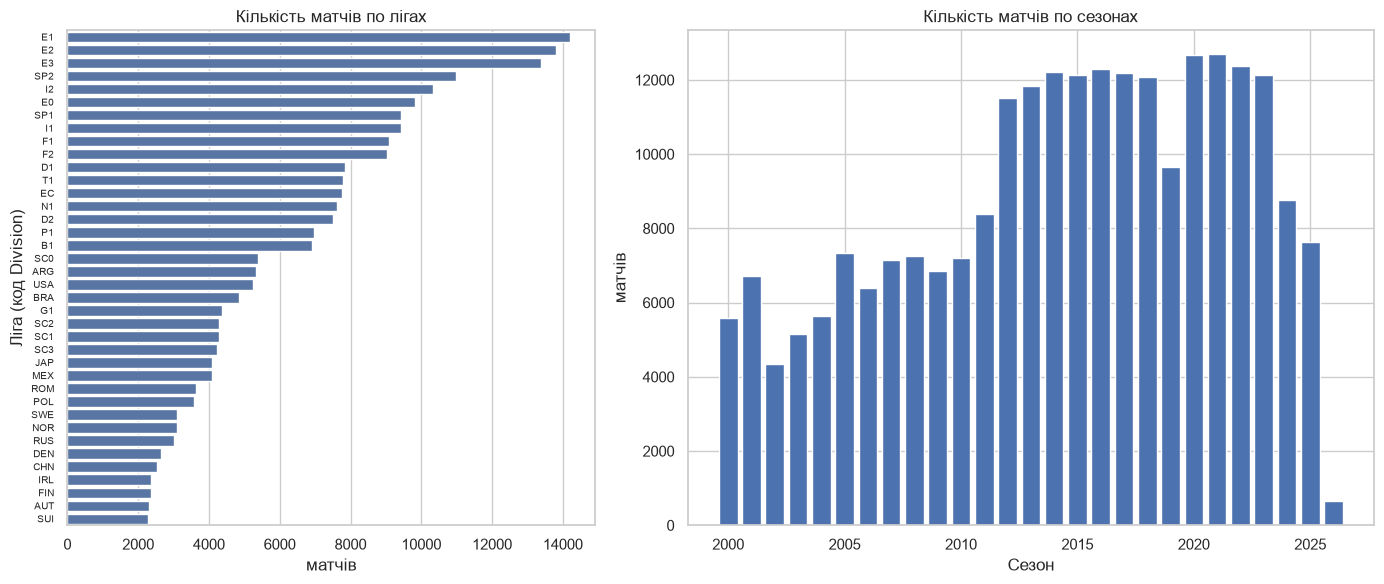

Ліг у сезоні: {2000: 16, 2001: 20, 2002: 20, 2003: 20, 2004: 20, 2005: 21, 2006: 19, 2007: 21, 2008: 21, 2009: 20, 2010: 21, 2011: 35, 2012: 37, 2013: 38, 2014: 38, 2015: 38, 2016: 38, 2017: 38, 2018: 38, 2019: 38, 2020: 38, 2021: 38, 2022: 37, 2023: 37, 2024: 38, 2025: 22, 2026: 22}


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.3]})
vc = m["Division"].value_counts()
sns.barplot(x=vc.values, y=vc.index, color="#4C72B0", ax=axes[0])
axes[0].set_title("Кількість матчів по лігах"); axes[0].set_xlabel("матчів"); axes[0].set_ylabel("Ліга (код Division)")
axes[0].tick_params(axis="y", labelsize=7)
ps = m.groupby("season").size()
axes[1].bar(ps.index, ps.values, color="#4C72B0")
axes[1].set_title("Кількість матчів по сезонах"); axes[1].set_xlabel("Сезон"); axes[1].set_ylabel("матчів")
fig.tight_layout(); save(fig, "matches_by_league_season"); plt.show()
print("Ліг у сезоні:", m.groupby("season")["Division"].nunique().to_dict())

## 4. Розподіл H / D / A: загалом, у топ-5 лігах, у часі

In [7]:
print("Загалом, %:", (m["FTResult"].value_counts(normalize=True)[config.CLASSES] * 100).round(1).to_dict())
top5 = m[m["Division"].isin(config.TOP5)]
t5 = pd.crosstab(top5["Division"].map(config.TOP5), top5["FTResult"], normalize="index")[config.CLASSES] * 100
t5.loc["Усі ліги"] = m["FTResult"].value_counts(normalize=True)[config.CLASSES] * 100
print(t5.round(1).to_string())

Загалом, %: {'H': 44.6, 'D': 26.5, 'A': 28.9}
FTResult       H     D     A
Division                    
АПЛ         45.7  24.7  29.6
Бундесліга  45.6  24.7  29.7
Ла Ліга     47.2  25.2  27.6
Ліга 1      45.0  27.7  27.2
Серія A     44.4  27.0  28.6
Усі ліги    44.6  26.5  28.9


збережено: reports/figures/eda_result_distribution.png


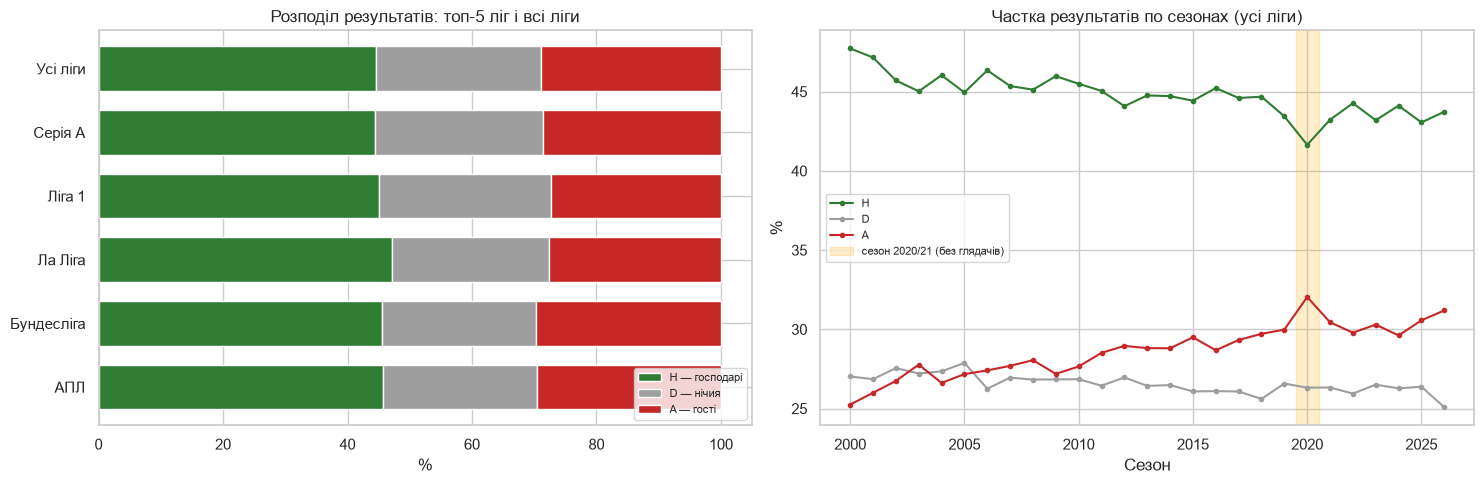

FTResult     H     D     A
season                    
2017      44.6  26.1  29.3
2018      44.7  25.6  29.7
2019      43.4  26.6  30.0
2020      41.6  26.3  32.0
2021      43.2  26.3  30.4
2022      44.3  25.9  29.8
2023      43.2  26.5  30.3
2024      44.1  26.3  29.6
2025      43.1  26.4  30.6
2026      43.7  25.1  31.2


In [8]:
res = pd.crosstab(m["season"], m["FTResult"], normalize="index")[config.CLASSES] * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
t5[config.CLASSES].plot.barh(stacked=True, color=[PAL[c] for c in config.CLASSES], ax=axes[0], width=0.7)
axes[0].set_title("Розподіл результатів: топ-5 ліг і всі ліги"); axes[0].set_xlabel("%"); axes[0].set_ylabel("")
axes[0].legend(["H — господарі", "D — нічия", "A — гості"], loc="lower right", fontsize=8)
for c in config.CLASSES:
    axes[1].plot(res.index, res[c], marker="o", ms=3, color=PAL[c], label=c)
axes[1].axvspan(2019.5, 2020.5, color="orange", alpha=0.2, label="сезон 2020/21 (без глядачів)")
axes[1].set_title("Частка результатів по сезонах (усі ліги)"); axes[1].set_xlabel("Сезон"); axes[1].set_ylabel("%")
axes[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "result_distribution"); plt.show()
print(res.round(1).loc[2017:].to_string())

Сезон 2020/21 (порожні трибуни через COVID-19) — помітний провал переваги домашнього поля: частка перемог господарів падає, гостей — зростає. Для моделі це означає, що «бонус господарів» не константа, і трохи дрейфує в часі.

## 5. Голи

Середнє голів за матч: 2.64 (господарі 1.49, гості 1.15)
Частка матчів з тоталом > 2.5: 49.2%
Найчастіші рахунки, %: {'1:1': 12.3, '1:0': 10.5, '2:1': 8.9, '0:0': 7.9, '0:1': 7.7, '2:0': 7.6, '1:2': 6.7, '2:2': 5.2}


збережено: reports/figures/eda_goals.png


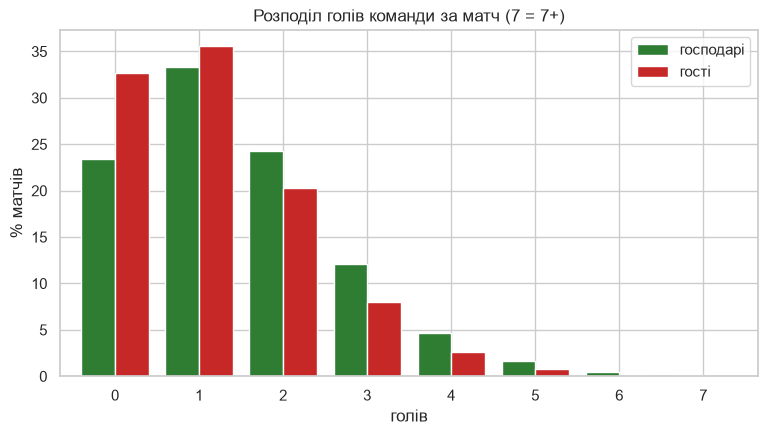

In [9]:
m["total_goals"] = m["FTHome"] + m["FTAway"]
print(f"Середнє голів за матч: {m['total_goals'].mean():.2f} (господарі {m['FTHome'].mean():.2f}, гості {m['FTAway'].mean():.2f})")
print(f"Частка матчів з тоталом > 2.5: {(m['total_goals'] > 2.5).mean():.1%}")
print("Найчастіші рахунки, %:", (m["FTHome"].astype(int).astype(str) + ":" + m["FTAway"].astype(int).astype(str)).value_counts(normalize=True).head(8).mul(100).round(1).to_dict())
fig, ax = plt.subplots(figsize=(9, 4.5))
g = pd.DataFrame({"господарі": m["FTHome"].clip(upper=7).value_counts(normalize=True),
                  "гості": m["FTAway"].clip(upper=7).value_counts(normalize=True)}).sort_index() * 100
g.plot.bar(ax=ax, color=[PAL["H"], PAL["A"]], width=0.8)
ax.set_title("Розподіл голів команди за матч (7 = 7+)"); ax.set_xlabel("голів"); ax.set_ylabel("% матчів")
ax.set_xticklabels([int(i) for i in g.index], rotation=0)
save(fig, "goals"); plt.show()

## 6. Різниця Elo і результат
`HomeElo − AwayElo` — передматчеві рейтинги (ознака без витоку). Наскільки вона пояснює результат?

FTResult             H     D     A      n
bin                                      
(-inf, -300.0]    10.7  17.7  71.7   2862
(-300.0, -200.0]  19.6  24.1  56.3   6225
(-200.0, -150.0]  25.4  26.6  48.0   6499
(-150.0, -100.0]  31.4  28.6  40.0  11653
(-100.0, -50.0]   36.2  29.9  33.9  18566
(-50.0, 0.0]      41.3  30.2  28.5  24738
(0.0, 50.0]       46.9  29.0  24.2  24384
(50.0, 100.0]     52.7  26.9  20.3  18616
(100.0, 150.0]    59.4  24.6  16.0  11516
(150.0, 200.0]    66.7  20.1  13.2   6569
(200.0, 300.0]    75.1  16.5   8.4   6237
(300.0, inf]      85.5  10.8   3.8   2846


збережено: reports/figures/eda_elo_diff_vs_result.png


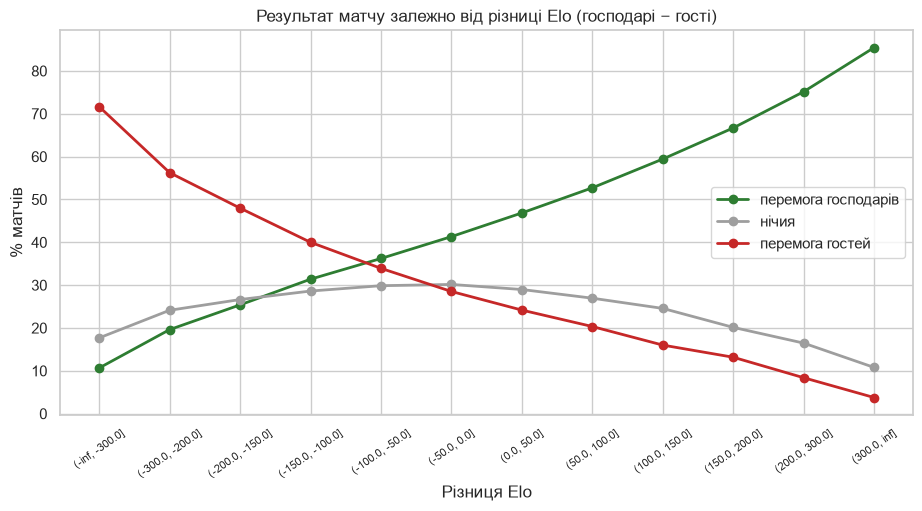

Кореляція elo_diff з (голи господарів − голи гостей): 0.381
Accuracy правила «перемагає команда з вищим Elo (з бонусом +65 господарям)»: 49.6%


In [10]:
e = m.dropna(subset=["HomeElo", "AwayElo"]).copy()
e["elo_diff"] = e["HomeElo"] - e["AwayElo"]
bins = [-np.inf, -300, -200, -150, -100, -50, 0, 50, 100, 150, 200, 300, np.inf]
e["bin"] = pd.cut(e["elo_diff"], bins)
eb = pd.crosstab(e["bin"], e["FTResult"], normalize="index")[config.CLASSES] * 100
eb["n"] = e["bin"].value_counts()
print(eb.round(1).to_string())
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(eb))
for c in config.CLASSES:
    ax.plot(x, eb[c], marker="o", color=PAL[c], label={"H": "перемога господарів", "D": "нічия", "A": "перемога гостей"}[c], lw=2)
ax.set_xticks(x); ax.set_xticklabels([str(i) for i in eb.index], rotation=35, fontsize=8)
ax.set_title("Результат матчу залежно від різниці Elo (господарі − гості)")
ax.set_xlabel("Різниця Elo"); ax.set_ylabel("% матчів"); ax.legend()
save(fig, "elo_diff_vs_result"); plt.show()
print(f"Кореляція elo_diff з (голи господарів − голи гостей): {e['elo_diff'].corr(e['FTHome'] - e['FTAway']):.3f}")
print(f"Accuracy правила «перемагає команда з вищим Elo (з бонусом +65 господарям)»: "
      f"{(np.where(e['elo_diff'] + 65 > 0, 'H', 'A') == e['FTResult']).mean():.1%}")

## 7. Коефіцієнти букмекерів: маржа, точність, калібрування
Імовірності без маржі: `p_i = (1/odd_i) / Σ(1/odd_j)`.

In [11]:
o = m.dropna(subset=["OddHome", "OddDraw", "OddAway"]).copy()
o = o[(o[["OddHome", "OddDraw", "OddAway"]] > 1).all(axis=1)]
inv = 1 / o[["OddHome", "OddDraw", "OddAway"]]
o["margin"] = inv.sum(axis=1) - 1
P = inv.div(inv.sum(axis=1), axis=0).values
o["pred"] = np.array(config.CLASSES)[P.argmax(1)]
Y = pd.get_dummies(o["FTResult"])[config.CLASSES].values.astype(float)
print(f"Матчів із коефіцієнтами: {len(o):,} ({len(o)/len(m):.1%})")
print(f"Маржа БК: медіана {o['margin'].median():.1%}, середня {o['margin'].mean():.1%}")
print(f"Accuracy фаворита БК: {(o['pred'] == o['FTResult']).mean():.1%}")
print("Що прогнозує фаворит БК, %:", (o["pred"].value_counts(normalize=True) * 100).round(2).to_dict())
print(f"Log loss БК: {-(Y * np.log(P)).sum(1).mean():.4f};  Brier (multi): {((P - Y) ** 2).sum(1).mean():.4f}")
freq = Y.mean(0)
print(f"Log loss «частоти класів» (наївний бейзлайн): {-(Y * np.log(freq)).sum(1).mean():.4f}")
mt = o.groupby("season")["margin"].median() * 100
print("Медіанна маржа по сезонах, %:", mt.round(1).to_dict())

Матчів із коефіцієнтами: 235,806 (98.7%)
Маржа БК: медіана 6.7%, середня 7.3%
Accuracy фаворита БК: 50.1%
Що прогнозує фаворит БК, %: {'H': 74.0, 'A': 25.81, 'D': 0.19}
Log loss БК: 1.0056;  Brier (multi): 0.6018
Log loss «частоти класів» (наївний бейзлайн): 1.0710
Медіанна маржа по сезонах, %: {2000: 12.8, 2001: 11.8, 2002: 12.2, 2003: 11.9, 2004: 12.0, 2005: 11.4, 2006: 10.9, 2007: 9.5, 2008: 6.7, 2009: 6.5, 2010: 6.6, 2011: 6.5, 2012: 6.6, 2013: 6.6, 2014: 6.6, 2015: 6.5, 2016: 6.5, 2017: 6.4, 2018: 6.3, 2019: 6.6, 2020: 6.5, 2021: 6.3, 2022: 6.3, 2023: 6.4, 2024: 6.4, 2025: 7.7, 2026: 8.2}


збережено: reports/figures/eda_bookmaker_calibration.png


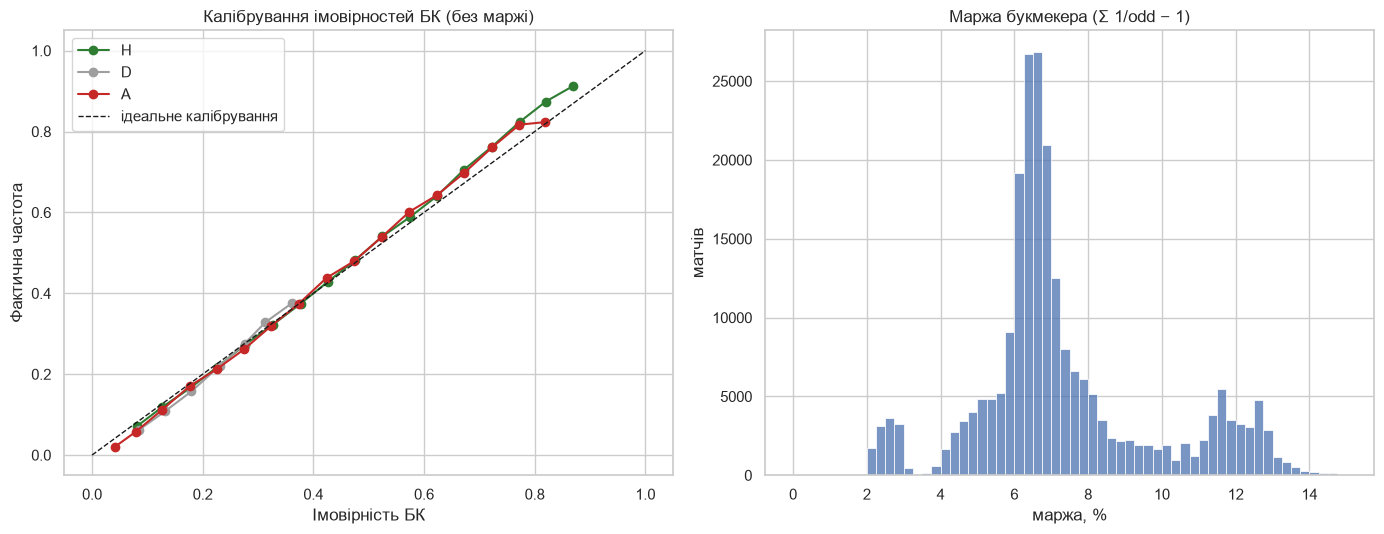

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
edges = np.linspace(0, 1, 21)
for k, c in enumerate(config.CLASSES):
    b = pd.cut(P[:, k], edges)
    cal = pd.DataFrame({"p": P[:, k], "y": Y[:, k], "b": b}).groupby("b", observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    cal = cal[cal["n"] >= 100]
    axes[0].plot(cal["p"], cal["y"], marker="o", color=PAL[c], label=c)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="ідеальне калібрування")
axes[0].set_title("Калібрування імовірностей БК (без маржі)")
axes[0].set_xlabel("Імовірність БК"); axes[0].set_ylabel("Фактична частота"); axes[0].legend()
sns.histplot(o["margin"] * 100, bins=60, binrange=(0, 15), ax=axes[1], color="#4C72B0")
axes[1].set_title("Маржа букмекера (Σ 1/odd − 1)"); axes[1].set_xlabel("маржа, %"); axes[1].set_ylabel("матчів")
fig.tight_layout(); save(fig, "bookmaker_calibration"); plt.show()

Імовірності БК майже ідеально відкалібровані для H і A. Нічия — проблемний клас: БК майже ніколи не ставить її фаворитом, а її імовірність стиснута в вузький діапазон ~0.2–0.33. Accuracy фаворита БК (~50%) — орієнтир-стеля для моделі.

## 8. Національні збірні

In [13]:
r = pd.read_csv(RAW / "results.csv", parse_dates=["date"])
sh = pd.read_csv(RAW / "shootouts.csv", parse_dates=["date"])
fn = pd.read_csv(RAW / "former_names.csv")
print(f"results.csv: {len(r):,} матчів, {r['date'].min().date()} … {r['date'].max().date()}; former_names: {len(fn)} перейменувань")
r = r.dropna(subset=["home_score", "away_score"])
r["res"] = np.select([r.home_score > r.away_score, r.home_score == r.away_score], ["H", "D"], "A")
r2 = r[r["date"] >= config.MIN_DATE].copy()
t = r2["tournament"]
r2["type"] = np.select([t.eq("Friendly"), t.str.contains("qualification", case=False)], ["товариський", "відбір"],
                        np.where(t.str.contains("World Cup|Euro|Copa Am|African Cup|Asian Cup|Gold Cup|Nations League", case=False), "фінальний турнір / ЛН", "інше"))
print(f"З 2000 року: {len(r2):,} матчів, {pd.concat([r2.home_team, r2.away_team]).nunique()} збірних, {r2.tournament.nunique()} турнірів")
print((r2["type"].value_counts(normalize=True) * 100).round(1).to_dict())
print("Топ турнірів:", r2["tournament"].value_counts().head(8).to_dict())

results.csv: 49,940 матчів, 1872-11-30 … 2026-10-06; former_names: 36 перейменувань
З 2000 року: 25,879 матчів, 322 збірних, 140 турнірів
{'відбір': 38.8, 'товариський': 32.5, 'інше': 15.1, 'фінальний турнір / ЛН': 13.6}
Топ турнірів: {'Friendly': 8406, 'FIFA World Cup qualification': 5840, 'UEFA Euro qualification': 1532, 'African Cup of Nations qualification': 1476, 'UEFA Nations League': 762, 'AFC Asian Cup qualification': 530, 'African Cup of Nations': 525, 'CONCACAF Nations League': 495}


збережено: reports/figures/eda_intl_overview.png


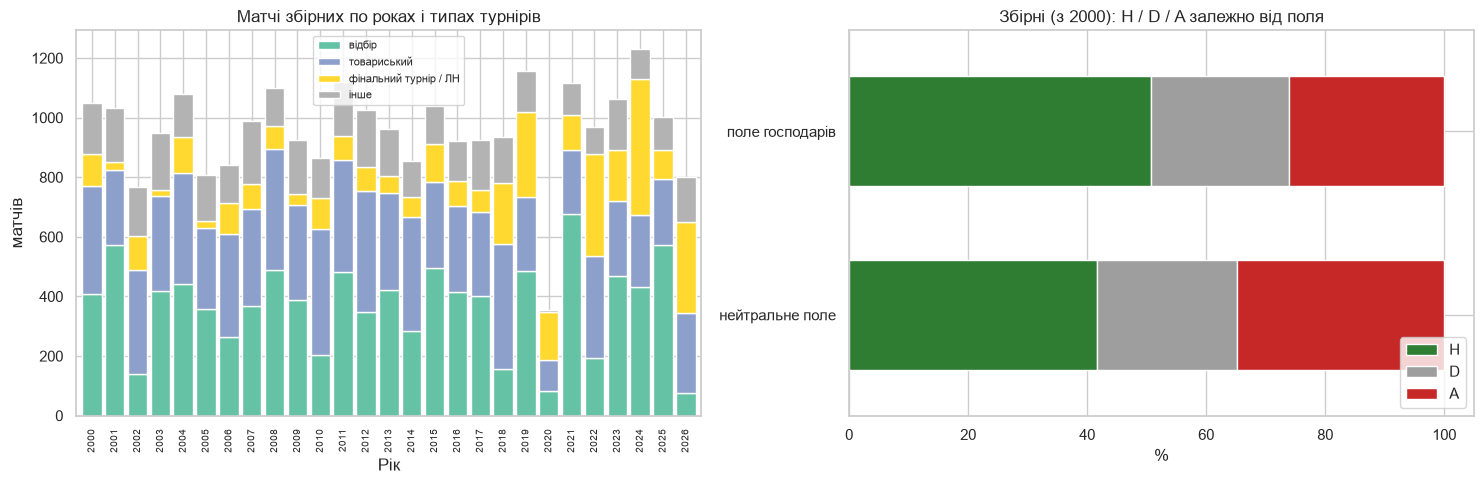

res                 H     D     A
neutral                          
нейтральне поле  41.6  23.6  34.7
поле господарів  50.8  23.1  26.2
Частка нейтральних матчів: 28.8%
res                       H     D     A
type                                   
відбір                 50.1  20.7  29.2
товариський            47.8  26.8  25.5
фінальний турнір / ЛН  45.1  23.6  31.2
інше                   46.7  21.7  31.6


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
yt = pd.crosstab(r2["date"].dt.year, r2["type"])
yt.plot.bar(stacked=True, ax=axes[0], width=0.85, colormap="Set2")
axes[0].set_title("Матчі збірних по роках і типах турнірів"); axes[0].set_xlabel("Рік"); axes[0].set_ylabel("матчів")
axes[0].tick_params(axis="x", labelsize=7); axes[0].legend(fontsize=8)
nt = pd.crosstab(r2["neutral"].map({True: "нейтральне поле", False: "поле господарів"}), r2["res"], normalize="index")[config.CLASSES] * 100
nt.plot.barh(stacked=True, color=[PAL[c] for c in config.CLASSES], ax=axes[1], width=0.6)
axes[1].set_title("Збірні (з 2000): H / D / A залежно від поля"); axes[1].set_xlabel("%"); axes[1].set_ylabel("")
axes[1].legend(["H", "D", "A"], loc="lower right")
fig.tight_layout(); save(fig, "intl_overview"); plt.show()
print(nt.round(1).to_string())
print("Частка нейтральних матчів:", f"{r2['neutral'].mean():.1%}")
print((pd.crosstab(r2["type"], r2["res"], normalize="index")[config.CLASSES] * 100).round(1).to_string())

In [15]:
sh2 = sh[sh["date"] >= config.MIN_DATE]
draws = r2[r2["res"] == "D"]
print(f"Серій пенальті з 2000 року: {len(sh2)}; це {len(sh2) / len(r2):.1%} усіх матчів і {len(sh2) / len(draws):.1%} нічиїх")
print("Ціль моделі — результат основного/додаткового часу: серія пенальті = нічия (D).")

Серій пенальті з 2000 року: 432; це 1.7% усіх матчів і 7.2% нічиїх
Ціль моделі — результат основного/додаткового часу: серія пенальті = нічия (D).


## 9. Висновки для моделювання

1. **Нічиї — найважчий клас.** 26.5% клубних матчів (~23% у збірних), але фаворит БК — нічия лише в 0.2% матчів, а за Elo частка нічиїх ніде не перевищує ~30%. Accuracy по нічиїх буде низькою; головні метрики — log loss / Brier, accuracy — додатково.
2. **Перевага домашнього поля реальна, але дрейфує**: 44.6% H проти 28.9% A. У ковідному сезоні 2020/21 частка H упала до 41.6%, а A зросла до 32.0%. Розбиття лише за часом обов'язкове.
3. **Різниця Elo — сильна ознака без витоку**: частка перемог господарів монотонно росте від 10.7% (Elo господарів нижче на 300+) до 85.5% (вище на 300+); кореляція з різницею голів 0.38. Але `HomeElo/AwayElo` є лише в ~63% матчів (немає в ARG, BRA, USA, JAP, MEX, CHN, IRL, SUI і більшості матчів E2/E3/EC/SC1–3).
4. **Коефіцієнти БК — сильний бейзлайн**: є в 98.7% матчів, після зняття маржі (медіана 6.7%; до 2008 р. ~12%) майже ідеально відкалібровані. Фаворит БК вгадує 50.1% матчів, log loss 1.006 проти 1.071 у наївного бейзлайну частот. Обіграти ринок навряд чи вийде; цікавіша модель без коефіцієнтів.
5. **Пропуски нерівномірні**: удари/кутові/картки відсутні в ~49% матчів (неєвропейські й скандинавські ліги — 0%), Max* і тотали — в 12–34%. Ковзні ознаки зі статистики мають допускати NaN (LightGBM це вміє) або обмежуватися голами, які є скрізь.
6. **Нерівний обсяг по лігах і сезонах**: до 2010/11 — 16–21 ліга, з 2011/12 — 35–38 (додались ARG, BRA, USA, скандинави тощо). Сезон 2025/26 неповний. Ліга як категоріальна ознака врахує різний рівень нічиїх і переваги поля.
7. **Збірні**: 28.8% матчів з 2000 року — на нейтральному полі; там H 41.6% / A 34.7% проти 50.8% / 26.2% вдома → бонус поля в Elo лише для не нейтральних матчів, `neutral` — окрема ознака. У товариських найбільше нічиїх (26.8%). Серій пенальті — 432 (1.7% матчів), для цілі це нічия.
8. **Витік**: FT*/HT*, удари, кутові, фоли, картки цього матчу і `C_*` кластери — лише для аналізу, ніколи не як ознаки.